In [12]:
import pandas as pd

In [13]:
df = pd.read_csv('isoc_ec_ib20_linear.csv.gz', compression='gzip')

df.head()

,DATAFLOW,LAST UPDATE,freq,ind_type,indic_is,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Albania,2020,NaN,u,NaN
1,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2020,11.73,NaN,NaN
2,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2021,10.10,NaN,NaN
3,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2022,9.99,NaN,NaN
4,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2023,9.27,NaN,NaN


In [14]:
df.shape

(558750, 11)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558750 entries, 0 to 558749
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATAFLOW     558750 non-null  object 
 1   LAST UPDATE  558750 non-null  object 
 2   freq         558750 non-null  object 
 3   ind_type     558750 non-null  object 
 4   indic_is     558750 non-null  object 
 5   unit         558750 non-null  object 
 6   geo          558750 non-null  object 
 7   TIME_PERIOD  558750 non-null  int64  
 8   OBS_VALUE    530838 non-null  float64
 9   OBS_FLAG     75004 non-null   object 
 10  CONF_STATUS  0 non-null       float64
dtypes: float64(2), int64(1), object(8)
memory usage: 46.9+ MB


In [16]:
df.isnull().sum()

,0
DATAFLOW,0
LAST UPDATE,0
freq,0
ind_type,0
indic_is,0
unit,0
geo,0
TIME_PERIOD,0
OBS_VALUE,27912
OBS_FLAG,483746


**Análise de valores ausentes**

Foi realizada uma verificação dos valores ausentes em todas as colunas da base de dados. Identificamos 27.912 valores ausentes na coluna `OBS_VALUE`, 483.746 na coluna `OBS_FLAG` e 558.750 na coluna `CONF_STATUS`. As demais colunas não apresentam valores ausentes.

Essa verificação permite identificar quais informações precisam ser avaliadas durante o tratamento dos dados.

In [17]:
df = df.drop(columns=['CONF_STATUS'])

In [18]:
df.shape


(558750, 10)

**Remoção de coluna sem informações**

Durante a análise dos valores ausentes, identificamos que a coluna `CONF_STATUS` estava totalmente vazia, apresentando 558.750 valores ausentes. Por esse motivo, realizamos sua remoção da base de dados, utilizando a biblioteca Pandas.

Essa decisão permite eliminar uma coluna que não acrescenta informações à análise, mantendo as demais variáveis do conjunto de dados.

In [19]:
df_sem_valor = df[df['OBS_VALUE'].isna()]

df_sem_valor['OBS_FLAG'].value_counts(dropna=False)

,count
OBS_FLAG,
u,27649
bu,263


**Investigação dos valores ausentes em OBS_VALUE**

Após identificar os registros sem valores na coluna `OBS_VALUE`, realizamos uma análise da coluna `OBS_FLAG` para verificar as marcações associadas a essas ausências.

Foram identificados 27.649 registros com a marcação `u` e 263 registros com a marcação `bu`, totalizando 27.912 registros sem valor numérico.

Essa análise demonstra que os valores ausentes estão associados a marcações específicas na base de dados. Por isso, antes de realizar qualquer exclusão ou preenchimento, precisamos compreender o significado dessas marcações.

In [20]:
df_sem_valor['geo'].value_counts()

,count
geo,
Slovakia,1692
Croatia,1586
Montenegro,1485
Ireland,1428
Bulgaria,1361
Slovenia,1281
Cyprus,1137
Serbia,1072
Romania,1029


**Distribuição dos valores ausentes por país**

Nesta etapa, analisamos a distribuição dos registros sem valores na coluna `OBS_VALUE` de acordo com o país (`geo`).

Os resultados demonstraram que a Eslováquia apresenta o maior número de registros ausentes, com 1.692 ocorrências, seguida pela Croácia, com 1.586, e Montenegro, com 1.485. Entre os países apresentados, a Turquia possui o menor número, com 78 ocorrências.

Essa análise permite identificar como os valores ausentes estão distribuídos geograficamente. Entretanto, a quantidade absoluta não representa necessariamente a proporção de dados ausentes de cada país, sendo necessário considerar também o total de registros por país.

In [21]:
(df_sem_valor['geo'].value_counts() / df['geo'].value_counts() * 100).round(2)

,count
geo,
Albania,5.58
Austria,3.46
Belgium,2.48
Bosnia and Herzegovina,2.79
Bulgaria,8.14
Croatia,10.94
Cyprus,6.81
Czechia,4.17
Denmark,6.29


**Resultados da análise percentual dos valores ausentes por país**

A análise demonstrou diferenças na proporção de valores ausentes entre os países. Montenegro apresentou o maior percentual, com 12,50%, seguido pela Croácia, com 10,94%, Macedônia do Norte, com 10,59%, Reino Unido, com 10,33%, e Eslováquia, com 10,17%.

Por outro lado, os menores percentuais foram observados na Turquia (0,74%), França (0,94%) e Espanha (1,17%).

Esses resultados mostram que a ausência de informações não está distribuída igualmente entre os países. Essa diferença deve ser considerada durante o tratamento dos dados, para evitar que a análise do comportamento de compra online seja prejudicada.

Os valores apresentados como NaN para a União Europeia e a Zona do Euro não puderam ser calculados por essa operação e deverão ser avaliados separadamente.

In [22]:
df_sem_valor['TIME_PERIOD'].value_counts().sort_index()

,count
TIME_PERIOD,
2020,3136
2021,3037
2022,2660
2023,2601
2024,10814
2025,5664


**Análise dos valores ausentes por ano**

Nesta etapa, analisamos a distribuição dos valores ausentes na coluna `OBS_VALUE` ao longo dos anos de 2020 a 2025.

Os resultados identificaram a seguinte distribuição:

- 2020: 3.136 registros;
- 2021: 3.037 registros;
- 2022: 2.660 registros;
- 2023: 2.601 registros;
- 2024: 10.814 registros;
- 2025: 5.664 registros.

Observamos uma concentração maior de valores ausentes em 2024, seguido por 2025. Esse resultado demonstra que as ausências não estão distribuídas igualmente ao longo do período analisado e devem ser consideradas no tratamento dos dados, especialmente nas comparações entre anos.

In [23]:
df.groupby('TIME_PERIOD')['OBS_VALUE'].count()

,OBS_VALUE
TIME_PERIOD,
2020,95180
2021,98563
2022,60171
2023,104514
2024,58073
2025,114337


**Análise dos registros válidos por ano**

Nesta etapa, verificamos a quantidade de registros com valores disponíveis na coluna `OBS_VALUE` para cada ano do período analisado.

Foram identificados os seguintes resultados:

- 2020: 95.180 registros válidos;
- 2021: 98.563 registros válidos;
- 2022: 60.171 registros válidos;
- 2023: 104.514 registros válidos;
- 2024: 58.073 registros válidos;
- 2025: 114.337 registros válidos.

Ao comparar esses resultados com os valores ausentes, observamos que 2024 apresenta a maior proporção de ausências, aproximadamente 15,7%. Esse fator merece atenção, pois pode influenciar as comparações entre os anos.

A análise contribui para identificar a disponibilidade dos dados e orientar as decisões da etapa de tratamento.

In [24]:
df_sem_valor['OBS_FLAG'].value_counts()

,count
OBS_FLAG,
u,27649
bu,263


**Análise das marcações dos valores ausentes**

Foi realizada uma análise dos códigos presentes na coluna `OBS_FLAG` para compreender as características dos registros sem valores em `OBS_VALUE`.

Foram identificadas duas marcações: `u`, presente em 27.649 registros, e `bu`, presente em 263 registros.

De acordo com a classificação do Eurostat, o código `u` indica baixa confiabilidade estatística, enquanto `b` indica uma quebra na série temporal. A combinação `bu` representa a presença das duas marcações.

Essas informações são importantes para avaliar a qualidade dos dados e orientar as decisões de tratamento. Portanto, não devemos substituir os valores ausentes por zero ou pela média sem justificativa estatística.

In [25]:
df['OBS_VALUE'].notna().sum(), df['OBS_VALUE'].isna().sum()

(np.int64(530838), np.int64(27912))

**Verificação dos registros válidos e ausentes**

Após a investigação dos valores ausentes, verificamos a quantidade total de registros preenchidos e não preenchidos na coluna `OBS_VALUE`.

A base apresenta 530.838 registros com valores numéricos e 27.912 registros sem valores, totalizando 558.750 observações.

Isso significa que aproximadamente 95% dos registros possuem informações disponíveis, enquanto cerca de 5% apresentam valores ausentes.

Com essa verificação, concluímos a análise inicial das ausências e podemos avançar para o tratamento dos dados, preservando os registros que possuem informações válidas.

In [26]:
df_tratado = df.dropna(subset=['OBS_VALUE']).copy()

df_tratado.shape

(530838, 10)

**Tratamento dos valores ausentes**

Nesta etapa, realizamos o tratamento dos dados ausentes na coluna `OBS_VALUE`, removendo os registros que não apresentavam valores numéricos.

Para preservar a base original, criamos uma cópia tratada, denominada `df_tratado`, utilizando a função `dropna()` da biblioteca Pandas.

Após o procedimento, verificamos as dimensões da nova base por meio da função `shape`, obtendo 530.838 registros e 10 colunas. Dessa forma, foram removidos 27.912 registros sem valores em `OBS_VALUE`, mantendo as observações que possuem informações numéricas disponíveis para as próximas análises.

In [27]:
df_tratado.duplicated().sum()

np.int64(0)

Verificação de registros duplicados

Nesta etapa, verificamos a existência de registros duplicados na base de dados tratada, utilizando as funções duplicated() e sum() da biblioteca Pandas. O resultado foi zero, indicando que não foram encontradas linhas duplicadas. Portanto, não foi necessário realizar a remoção de registros por duplicidade.

In [28]:
df_tratado.isnull().sum()

,0
DATAFLOW,0
LAST UPDATE,0
freq,0
ind_type,0
indic_is,0
unit,0
geo,0
TIME_PERIOD,0
OBS_VALUE,0
OBS_FLAG,483746


Verificação dos valores ausentes após o tratamento

Após a remoção dos registros sem valores na coluna OBS_VALUE, realizamos uma nova verificação dos dados ausentes utilizando as funções isnull() e sum() da biblioteca Pandas.

Os resultados mostraram que todas as colunas estão completas, com exceção de OBS_FLAG, que apresenta 483.746 valores ausentes.

Como OBS_FLAG é uma coluna auxiliar utilizada para registrar marcações relacionadas aos dados, seus valores ausentes não comprometem diretamente a análise dos percentuais disponíveis em OBS_VALUE.

Dessa forma, confirmamos que a variável principal do projeto não apresenta mais valores ausentes.

In [29]:
df_tratado['OBS_FLAG'].value_counts(dropna=False)

,count
OBS_FLAG,
NaN,483746
u,31384
b,10374
e,5045
bu,289


##**Análise da coluna OBS_FLAG**

Nesta etapa, analisamos a distribuição das marcações presentes na coluna OBS_FLAG, utilizando a função value_counts(dropna=False) da biblioteca Pandas.

Identificamos 483.746 registros sem marcação, além de 31.384 registros com o código u, 10.374 com b, 5.045 com e e 289 com bu.

Como essa coluna contém informações auxiliares relacionadas à qualidade e às características das observações, decidimos mantê-la na base de dados, preservando informações que poderão ser úteis na interpretação dos resultados.

In [30]:
df_tratado.head(10)

,DATAFLOW,LAST UPDATE,freq,ind_type,indic_is,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG
1,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2020,11.73,NaN
2,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2021,10.10,NaN
3,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2022,9.99,NaN
4,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2023,9.27,NaN
5,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2024,8.07,u
6,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Austria,2025,6.90,NaN
7,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Bosnia and Herzegovina,2020,13.22,NaN
8,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Belgium,2020,10.72,NaN
9,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Belgium,2021,9.59,NaN
10,ESTAT:ISOC_EC_IB20(1.0),17/04/26 11:00:00,Annual,Individuals who are born in another EU Member ...,Last online purchase: between 3 and 12 months ago,Percentage of individuals,Belgium,2022,9.55,NaN


In [31]:
df_tratado[['DATAFLOW', 'LAST UPDATE', 'freq', 'unit']].nunique()

,0
DATAFLOW,1
LAST UPDATE,1
freq,1
unit,4


### Visualização da base de dados tratada

Nesta etapa, utilizamos a função `head(10)` da biblioteca Pandas para visualizar as dez primeiras linhas da base de dados tratada.

A análise permitiu identificar as principais variáveis relacionadas ao objetivo do projeto, como o grupo de consumidores (`ind_type`), o indicador de comportamento de compra online (`indic_is`), o país (`geo`), o ano (`TIME_PERIOD`) e o percentual observado (`OBS_VALUE`).

Também identificamos colunas auxiliares e técnicas, que serão avaliadas para determinar sua relevância nas próximas etapas.

### Verificação dos valores únicos das colunas técnicas

Em seguida, utilizamos a função `nunique()` para verificar a quantidade de valores diferentes nas colunas `DATAFLOW`, `LAST UPDATE`, `freq` e `unit`.

Os resultados mostraram que as colunas `DATAFLOW`, `LAST UPDATE` e `freq` possuem apenas um valor único cada, enquanto a coluna `unit` apresenta quatro valores diferentes.

Essa verificação é importante para identificar variáveis que não apresentam variação entre os registros e avaliar sua necessidade na análise.

Como resultado, identificamos três colunas que poderão ser removidas posteriormente. Entretanto, nenhuma coluna foi excluída nesta etapa, pois ainda precisamos investigar os valores presentes em `unit` antes de concluir a seleção das variáveis.

In [32]:
df_tratado['unit'].value_counts()

,count
unit,
Percentage of individuals,199034
Percentage of individuals who used internet within the last year,178256
Percentage of individuals who used internet in the last 3 months,88302
Percentage of individuals who purchased online in the last 3 months,65246


### Análise das unidades de medida

Nesta etapa, utilizamos a função `value_counts()` da biblioteca Pandas para identificar os valores presentes na coluna `unit` e a quantidade de registros associados a cada unidade de medida.

Foram identificadas quatro categorias: percentual de indivíduos (199.034 registros), percentual de indivíduos que utilizaram a internet no último ano (178.256 registros), percentual de indivíduos que utilizaram a internet nos últimos três meses (88.302 registros) e percentual de indivíduos que realizaram compras online nos últimos três meses (65.246 registros).

Essa análise demonstrou que os percentuais disponíveis na base utilizam diferentes populações de referência. Portanto, é necessário considerar a unidade de medida ao realizar comparações, evitando interpretações incorretas.

Dessa forma, decidimos manter a coluna `unit` na base de dados, pois ela contém informações essenciais para a análise do comportamento de compra online dos consumidores europeus.

In [33]:
df_tratado = df_tratado.drop(columns=['DATAFLOW', 'LAST UPDATE', 'freq'])

df_tratado.shape

(530838, 7)

### Remoção de colunas técnicas

Nesta etapa, realizamos a remoção das colunas `DATAFLOW`, `LAST UPDATE` e `freq`, utilizando a função `drop()` da biblioteca Pandas.

A decisão foi baseada na análise anterior, que demonstrou que essas três colunas apresentavam apenas um valor único em toda a base de dados.

Como essas informações não contribuem diretamente para identificar diferenças entre países, períodos ou grupos de consumidores, optamos por removê-las da base tratada, simplificando sua estrutura.

Após a remoção, utilizamos a função `shape` para verificar as dimensões da base, obtendo 530.838 registros e 7 colunas.

O procedimento não alterou a quantidade de registros nem os valores das variáveis utilizadas na análise do comportamento de compra online.

In [34]:
df_tratado['indic_is'].value_counts()

,count
indic_is,
Last online purchase: in the last 3 months,64062
Frequency of online purchases in the last 3 months: 1 or 2 times,45135
Frequency of online purchases in the last 3 months: 3 to 5 times,45131
Frequency of online purchases in the last 3 months: 6 times or more,45111
Frequency of online purchases in the last 3 months: 6 to 10 times,45087
Frequency of online purchases in the last 3 months: more than 10 times,45063
Last online purchase: in the 12 months,42815
Last online purchase: between 3 and 12 months ago,41433
Online purchases (3 months): other services than mentioned,40766


### Análise dos indicadores de comportamento de compra online

Nesta etapa, utilizamos a função `value_counts()` da biblioteca Pandas para identificar os diferentes indicadores presentes na coluna `indic_is` e a quantidade de registros associados a cada um.

Foram identificados 13 indicadores relacionados ao comportamento de compra online, incluindo o período desde a última compra realizada pela internet, a frequência de compras nos últimos três meses e uma categoria relacionada à aquisição de outros serviços.

Os resultados demonstram que a base permite analisar diferentes aspectos do consumo digital, especialmente a recência e a frequência das compras online.

Essa identificação é importante para selecionar os indicadores mais adequados aos objetivos do projeto e evitar comparações entre medidas que representam comportamentos distintos.

Nesta etapa, nenhuma informação foi removida da base de dados.

In [35]:
df_tratado['ind_type'].nunique()

147

In [36]:
df_tratado['ind_type'].unique()

array(['Individuals who are born in another EU Member State',
       'Individuals who are born in non-EU country',
       'Individuals who are foreign-born',
       'Individuals who are native-born',
       'Nationals of another EU-Member State',
       'Nationals of non-EU country', 'Non-nationals', 'Nationals',
       'Disability (activity limitation) - limited, but not severely',
       'Disability (activity limitation) - limited or severely limited',
       'Disability (activity limitation) - not limited at all',
       'Disability (activity limitation) - severely limited',
       'Individuals in the labour force (employed and unemployed)',
       'Persons aged 16-74 working in agriculture, forestry or fishing',
       'Persons aged 16-74 working in mining or quarrying',
       'Persons aged 16-74 working in manufacturing',
       'Working with a permanent job or under contract of unlimited duration',
       'Working with a temporary job or under contract of limited duration',
    

### Identificação dos grupos de consumidores

Nesta etapa, utilizamos as funções `nunique()` e `unique()` da biblioteca Pandas para identificar a quantidade e os nomes das categorias presentes na coluna `ind_type`.

Foram encontradas 147 categorias, que representam diferentes perfis da população, incluindo faixas etárias, sexo, escolaridade, renda, situação profissional, local de residência, nacionalidade e condições de deficiência.

Essa diversidade permite investigar como o comportamento de compra online varia entre diferentes grupos de consumidores, contribuindo para a identificação de padrões relevantes para estratégias de Marketing.

Também identificamos a categoria `All individuals`, que representa a população geral e poderá ser utilizada como ponto de partida para comparações entre países e períodos.

Nesta etapa, nenhuma categoria foi removida da base de dados.

In [37]:
df_tratado[df_tratado['ind_type'] == 'All individuals'].shape

(6461, 7)

### Verificação dos registros da população geral

Nesta etapa, utilizamos um filtro na coluna `ind_type` para identificar os registros pertencentes à categoria `All individuals`, que representa a população geral.

Em seguida, aplicamos a função `shape` para verificar as dimensões desse subconjunto de dados.

O resultado mostrou 6.461 registros e 7 colunas, indicando que a base contém informações sobre o comportamento de compra online da população geral.

Esses registros poderão servir como ponto de partida para analisar tendências de consumo digital entre países e ao longo dos anos.

Nesta etapa, nenhum registro foi removido da base original tratada.

In [38]:
df_tratado[df_tratado['ind_type'] == 'All individuals']['indic_is'].value_counts()

,count
indic_is,
Last online purchase: in the last 3 months,663
Frequency of online purchases in the last 3 months: 6 to 10 times,596
Frequency of online purchases in the last 3 months: 3 to 5 times,596
Frequency of online purchases in the last 3 months: more than 10 times,596
Frequency of online purchases in the last 3 months: 1 or 2 times,596
Frequency of online purchases in the last 3 months: 6 times or more,596
Online purchases (3 months): other services than mentioned,508
Last online purchase: between 3 and 12 months ago,442
Last online purchase: in the 12 months,442


### Análise dos indicadores disponíveis para a população geral

Nesta etapa, filtramos os registros da categoria `All individuals` e utilizamos a função `value_counts()` para verificar a distribuição dos indicadores presentes na coluna `indic_is`.

Identificamos 13 indicadores relacionados ao comportamento de compra online, abrangendo a recência das compras, a frequência de compras e a aquisição de outros serviços.

O indicador `Last online purchase: in the last 3 months` apresentou a maior quantidade de registros, totalizando 663 observações.

Considerando o objetivo do projeto, esse indicador foi escolhido como ponto de partida para investigar o comportamento de compra online da população geral em diferentes países e períodos.

A seleção não representa a exclusão definitiva dos demais indicadores, que poderão ser utilizados em análises complementares.

In [39]:
df_tratado[
    (df_tratado['ind_type'] == 'All individuals') &
    (df_tratado['indic_is'] == 'Last online purchase: in the last 3 months')
]['unit'].value_counts()

,count
unit,
Percentage of individuals,221
Percentage of individuals who used internet within the last year,221
Percentage of individuals who used internet in the last 3 months,221


### Definição da unidade de medida para a análise

Nesta etapa, verificamos as unidades de medida disponíveis para o indicador `Last online purchase: in the last 3 months`, considerando a categoria `All individuals`.

Foram identificadas três unidades de medida, cada uma com 221 registros.

Para a análise principal, selecionamos a unidade `Percentage of individuals`, pois ela permite estudar a proporção da população que realizou compras online nos últimos três meses, facilitando a comparação entre países e períodos.

Essa escolha evita misturar percentuais calculados sobre diferentes populações de referência.

In [40]:
df_analise = df_tratado[
    (df_tratado['ind_type'] == 'All individuals') &
    (df_tratado['indic_is'] == 'Last online purchase: in the last 3 months') &
    (df_tratado['unit'] == 'Percentage of individuals')
].copy()

df_analise.shape

(221, 7)

### Criação da base para análise do consumo online

Nesta etapa, criamos uma nova base de dados denominada `df_analise`, utilizando filtros na base tratada `df_tratado`.

Foram selecionados os registros da população geral (`All individuals`), considerando o indicador de última compra online nos três meses anteriores e a unidade de medida `Percentage of individuals`.

Após a aplicação dos filtros, a nova base apresentou 221 registros e 7 colunas.

Essa seleção permitirá iniciar a análise do comportamento de compra online entre países europeus e ao longo dos anos, utilizando uma medida consistente.

A base tratada completa foi preservada para futuras análises de outros perfis de consumidores e indicadores.

In [41]:
df_analise.groupby('TIME_PERIOD')['geo'].nunique()

,geo
TIME_PERIOD,
2020,38
2021,38
2022,34
2023,36
2024,37
2025,38


### Verificação da cobertura geográfica por ano

Nesta etapa, utilizamos as funções `groupby()` e `nunique()` da biblioteca Pandas para verificar a quantidade de países e regiões com registros disponíveis em cada ano da base de análise.

Os resultados mostraram 38 localidades em 2020, 38 em 2021, 34 em 2022, 36 em 2023, 37 em 2024 e 38 em 2025.

Observamos que a cobertura geográfica não é totalmente uniforme ao longo do período, sendo 2022 o ano com menor quantidade de localidades disponíveis.

Essa diferença deverá ser considerada nas análises temporais, evitando que mudanças na composição dos países sejam interpretadas incorretamente como alterações no comportamento de compra online.

In [42]:
df_analise.groupby('geo')['TIME_PERIOD'].nunique().value_counts().sort_index()

,count
TIME_PERIOD,
1,1
2,1
3,2
4,1
5,2
6,33


### Verificação da continuidade dos dados entre 2020 e 2025

Nesta etapa, verificamos a quantidade de anos disponíveis para cada país ou região, utilizando as funções `groupby()`, `nunique()`, `value_counts()` e `sort_index()` da biblioteca Pandas.

Os resultados mostraram que 33 localidades possuem registros em todos os seis anos analisados, enquanto 7 apresentam cobertura temporal incompleta.

Essa verificação é importante porque a comparação de diferentes anos pode ser influenciada pela ausência de informações de determinados países.

Dessa forma, identificamos a possibilidade de utilizar as 33 localidades com cobertura completa para realizar uma análise temporal mais consistente, mantendo a base de análise original preservada.

In [43]:
localidades_completas = (
    df_analise.groupby('geo')['TIME_PERIOD'].nunique()
)

localidades_completas = localidades_completas[
    localidades_completas == 6
].index

df_temporal = df_analise[
    df_analise['geo'].isin(localidades_completas)
].copy()

df_temporal.shape

(198, 7)

### Criação da base para análise temporal

Nesta etapa, criamos a base `df_temporal`, selecionando as localidades que possuem registros disponíveis em todos os anos do período de 2020 a 2025.

Para isso, utilizamos as funções `groupby()`, `nunique()` e `isin()` da biblioteca Pandas, identificando as localidades com cobertura temporal completa.

O resultado foi uma base com 198 registros e 7 colunas, correspondentes a 33 localidades observadas durante seis anos.

Essa seleção permite realizar comparações temporais mais consistentes, evitando alterações na composição das localidades analisadas entre os anos.

A base `df_analise` foi preservada para possíveis análises complementares.

In [44]:
sorted(df_temporal['geo'].unique())

['Albania',
 'Austria',
 'Belgium',
 'Bulgaria',
 'Croatia',
 'Cyprus',
 'Czechia',
 'Denmark',
 'Estonia',
 'Euro area (EA11-1999, EA12-2001, EA13-2007, EA15-2008, EA16-2009, EA17-2011, EA18-2014, EA19-2015, EA20-2023, EA21-2026)',
 'European Union - 27 countries (from 2020)',
 'Finland',
 'Germany',
 'Greece',
 'Hungary',
 'Ireland',
 'Italy',
 'Latvia',
 'Lithuania',
 'Luxembourg',
 'Malta',
 'Montenegro',
 'Netherlands',
 'Norway',
 'Poland',
 'Portugal',
 'Romania',
 'Serbia',
 'Slovakia',
 'Slovenia',
 'Spain',
 'Sweden',
 'Türkiye']

### Identificação das localidades da base temporal

Nesta etapa, utilizamos as funções `unique()` e `sorted()` para identificar as localidades presentes na base `df_temporal`.

Foram identificadas 33 localidades com registros completos entre 2020 e 2025, sendo 31 países e dois agregados regionais: União Europeia e zona do euro.

Como os agregados representam conjuntos de países, sua inclusão nas comparações entre países individuais poderia provocar distorções nos resultados.

Dessa forma, decidimos separar os agregados regionais da análise comparativa entre países, preservando-os na base anterior para possíveis análises complementares.

In [45]:
df_paises = df_temporal[
    ~df_temporal['geo'].str.startswith(
        ('European Union', 'Euro area')
    )
].copy()

df_paises.shape

(186, 7)

### Criação da base de análise por países

Nesta etapa, criamos a base `df_paises` a partir de `df_temporal`, removendo os registros referentes aos agregados regionais da União Europeia e da zona do euro.

Após a aplicação do filtro, a base apresentou 186 registros e 7 colunas, correspondentes a 31 países com informações disponíveis entre 2020 e 2025.

Essa preparação permite comparar a evolução do comportamento de compra online entre países, utilizando o mesmo conjunto de localidades em todos os anos.

As bases anteriores foram preservadas para possíveis análises complementares.

In [46]:
df_paises.groupby('TIME_PERIOD')['OBS_VALUE'].mean().round(2)

,OBS_VALUE
TIME_PERIOD,
2020,47.73
2021,53.18
2022,52.37
2023,55.23
2024,57.73
2025,59.62


In [47]:
comparacao_paises = df_paises.pivot(
    index='geo',
    columns='TIME_PERIOD',
    values='OBS_VALUE'
)

comparacao_paises['variacao_pp'] = (
    comparacao_paises[2025] - comparacao_paises[2020]
)

comparacao_paises[
    [2020, 2025, 'variacao_pp']
].sort_values('variacao_pp', ascending=False)

TIME_PERIOD,2020,2025,variacao_pp
geo,,,
Cyprus,31.11,58.21,27.10
Greece,38.28,62.85,24.57
Ireland,64.05,87.47,23.42
Serbia,28.99,50.50,21.51
Romania,22.11,41.53,19.42
Bulgaria,15.61,34.75,19.14
Slovakia,47.87,66.94,19.07
Türkiye,23.93,42.28,18.35
Albania,5.63,23.31,17.68


### Comparação do crescimento das compras online entre países (2020–2025)

Nesta etapa, utilizamos a função `pivot()` da biblioteca Pandas para organizar os percentuais de compras online por país e ano. Em seguida, calculamos a diferença, em pontos percentuais, entre os valores de 2025 e 2020.

Os resultados revelaram diferenças importantes na evolução do comportamento de compra online entre os 31 países analisados.

Chipre apresentou o maior crescimento, com aumento de 27,10 pontos percentuais, seguido por Grécia (24,57) e Irlanda (23,42). Em contrapartida, a Alemanha apresentou redução de 4,62 pontos percentuais, enquanto Luxemburgo registrou estabilidade, com variação de apenas 0,17 ponto percentual.

Esses resultados demonstram que a evolução do comércio eletrônico não ocorreu de maneira uniforme entre os países.

Para o Marketing Digital, essa diferença sugere a importância de considerar o nível de participação e o ritmo de crescimento de cada mercado. Países com participação elevada podem exigir estratégias diferentes daqueles em que as compras online ainda apresentam menor alcance.

Entretanto, os dados não permitem identificar, isoladamente, as causas dessas diferenças. A análise considera a proporção de indivíduos cuja última compra online ocorreu nos três meses anteriores, e não o volume financeiro das vendas ou o número de transações realizadas.

#Gráficos Comparativos

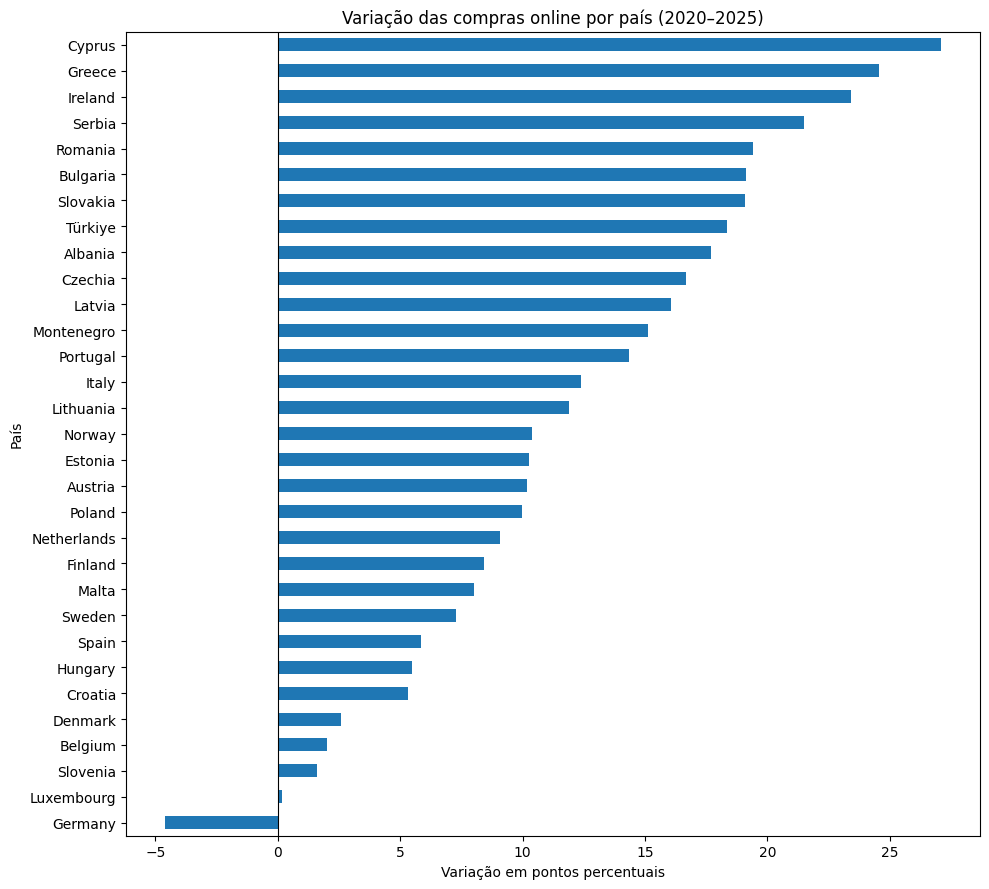

In [48]:
import matplotlib.pyplot as plt

variacoes = comparacao_paises['variacao_pp'].sort_values()

plt.figure(figsize=(10, 9))
variacoes.plot(kind='barh')

plt.title('Variação das compras online por país (2020–2025)')
plt.xlabel('Variação em pontos percentuais')
plt.ylabel('País')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [49]:
idades = sorted([
    grupo for grupo in df_tratado['ind_type'].unique()
    if 'years old' in grupo
])

for grupo in idades:
    print(grupo)

Females 25 to 54 years old
Females 35 to 44 years old
Females 45 to 54 years old
Females 55 to 64 years old
Females 55 to 74 years old
Females 65 to 74 years old
Females, 16 to 24 years old
Females, 16 to 74 years old
Females, 25 to 34 years old
Females, 25 to 64 years old
Individuals, 15 years old or less
Individuals, 16 to 17 years old
Individuals, 16 to 24 years old
Individuals, 25 to 34 years old
Individuals, 25 to 54 years old
Individuals, 25 to 64 years old
Individuals, 35 to 44 years old
Individuals, 45 to 54 years old
Individuals, 55 to 64 years old
Individuals, 55 to 74 years old
Individuals, 65 to 74 years old
Individuals, 75 years old or more
Males 25 to 54 years old
Males 35 to 44 years old
Males 45 to 54 years old
Males 55 to 64 years old
Males 55 to 74 years old
Males 65 to 74 years old
Males, 16 to 24 years old
Males, 16 to 74 years old
Males, 25 to 34 years old
Males, 25 to 64 years old


### Visualização da evolução das compras online entre países (2020–2025)

Nesta etapa, utilizamos a biblioteca Matplotlib para construir um gráfico de barras horizontais com a variação, em pontos percentuais, da participação nas compras online entre 2020 e 2025 nos 31 países selecionados.

O gráfico permite visualizar que o crescimento não ocorreu de maneira uniforme. Chipre apresentou a maior variação positiva, com 27,10 pontos percentuais, seguido por Grécia (24,57) e Irlanda (23,42).

Por outro lado, a Alemanha apresentou uma redução de 4,62 pontos percentuais, enquanto Luxemburgo registrou praticamente estabilidade, com crescimento de apenas 0,17 ponto percentual.

Esses resultados mostram que os mercados europeus apresentam diferentes estágios e ritmos de evolução no comportamento de compra online.

Para o Marketing Digital, essa diversidade reforça a importância de desenvolver estratégias adaptadas às características de cada mercado. Países com elevada participação nas compras online podem apresentar necessidades diferentes daqueles em que esse comportamento ainda é menos frequente.

Entretanto, o gráfico apresenta uma comparação entre dois anos específicos e não permite identificar as causas das variações observadas.

In [50]:
faixas_etarias = [
    'Individuals, 16 to 24 years old',
    'Individuals, 25 to 34 years old',
    'Individuals, 35 to 44 years old',
    'Individuals, 45 to 54 years old',
    'Individuals, 55 to 64 years old',
    'Individuals, 65 to 74 years old'
]

df_idades = df_tratado[
    (df_tratado['ind_type'].isin(faixas_etarias)) &
    (df_tratado['indic_is'] == 'Last online purchase: in the last 3 months') &
    (df_tratado['unit'] == 'Percentage of individuals') &
    (df_tratado['TIME_PERIOD'] == 2025) &
    (df_tratado['geo'].isin(df_paises['geo'].unique()))
].copy()

df_idades.groupby('ind_type')['geo'].nunique()

,geo
ind_type,
"Individuals, 16 to 24 years old",31
"Individuals, 25 to 34 years old",31
"Individuals, 35 to 44 years old",31
"Individuals, 45 to 54 years old",31
"Individuals, 55 to 64 years old",31
"Individuals, 65 to 74 years old",31


### Verificação da disponibilidade de dados por faixa etária

Nesta etapa, filtramos o conjunto de dados para analisar seis faixas etárias, considerando o indicador de compras online realizadas nos últimos três meses, a unidade de medida referente ao percentual de indivíduos e o ano de 2025.

Também restringimos a análise aos 31 países selecionados anteriormente, garantindo a continuidade do recorte geográfico do projeto.

A verificação demonstrou que todas as seis faixas etárias possuem informações disponíveis nos 31 países.

Esse resultado permite realizar uma comparação entre grupos etários com cobertura geográfica uniforme, contribuindo para uma análise mais consistente das diferenças no comportamento de compra online.

A próxima etapa será calcular os percentuais médios de cada faixa etária e identificar possíveis diferenças relevantes para a segmentação de Marketing Digital.

In [51]:
media_idades = (
    df_idades.groupby('ind_type')['OBS_VALUE']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

media_idades

,OBS_VALUE
ind_type,
"Individuals, 25 to 34 years old",75.87
"Individuals, 35 to 44 years old",72.17
"Individuals, 16 to 24 years old",70.08
"Individuals, 45 to 54 years old",62.37
"Individuals, 55 to 64 years old",46.30
"Individuals, 65 to 74 years old",30.03


### Análise das compras online por faixa etária em 2025

Nesta etapa, utilizamos as funções `groupby()`, `mean()` e `sort_values()` da biblioteca Pandas para calcular a média dos percentuais de participação nas compras online entre seis faixas etárias, considerando os 31 países selecionados.

Os resultados indicaram que a faixa de 25 a 34 anos apresentou a maior média de participação nas compras online (75,87%), seguida pelos grupos de 35 a 44 anos (72,17%) e de 16 a 24 anos (70,08%).

Entre os grupos de maior idade, foram observadas médias menores: 46,30% para indivíduos de 55 a 64 anos e 30,03% para aqueles de 65 a 74 anos.

A diferença entre os grupos de 25 a 34 anos e de 65 a 74 anos foi de 45,84 pontos percentuais.

Esses resultados evidenciam diferenças relevantes no comportamento de compra online entre faixas etárias, destacando a importância da segmentação de públicos nas estratégias de Marketing Digital.

Do ponto de vista social, a menor participação observada entre consumidores mais velhos justifica investigar possíveis barreiras de acesso, compreensão e confiança no ambiente digital.

Entretanto, os dados analisados não permitem identificar diretamente as causas dessas diferenças. Além disso, os resultados representam médias simples entre os 31 países, sem ponderação pelo tamanho das populações.

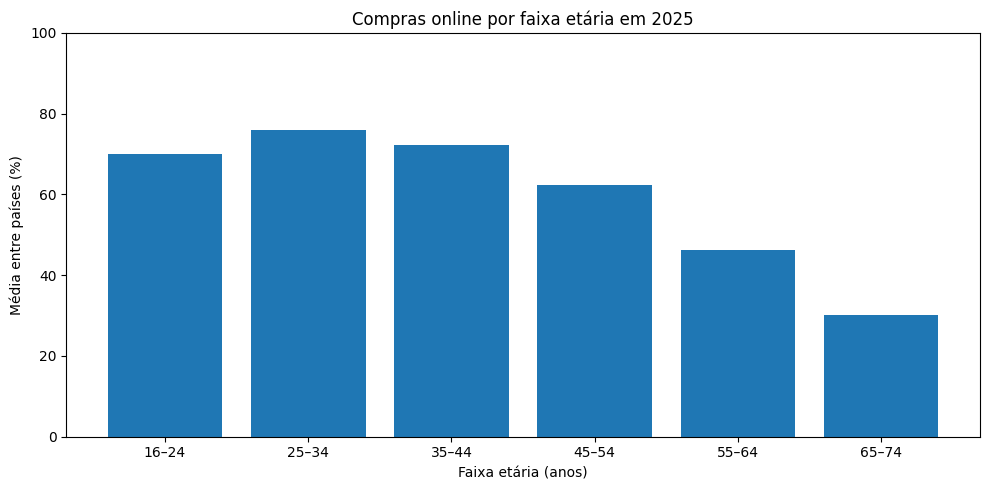

In [52]:
import matplotlib.pyplot as plt

ordem_idades = [
    'Individuals, 16 to 24 years old',
    'Individuals, 25 to 34 years old',
    'Individuals, 35 to 44 years old',
    'Individuals, 45 to 54 years old',
    'Individuals, 55 to 64 years old',
    'Individuals, 65 to 74 years old'
]

valores = media_idades.reindex(ordem_idades)

plt.figure(figsize=(10, 5))
plt.bar(
    ['16–24', '25–34', '35–44', '45–54', '55–64', '65–74'],
    valores
)

plt.title('Compras online por faixa etária em 2025')
plt.xlabel('Faixa etária (anos)')
plt.ylabel('Média entre países (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Visualização das diferenças de compras online por faixa etária

Nesta etapa, utilizamos a biblioteca Matplotlib para construir um gráfico de barras comparando a participação média nas compras online entre seis faixas etárias, considerando 31 países europeus em 2025.

O gráfico evidencia diferenças expressivas entre os grupos. A maior participação foi observada entre indivíduos de 25 a 34 anos (75,87%), enquanto a menor ocorreu entre pessoas de 65 a 74 anos (30,03%).

A diferença de 45,84 pontos percentuais entre esses grupos demonstra que a participação no comércio eletrônico varia significativamente conforme a faixa etária.

Para o Marketing Digital, os resultados reforçam a importância da segmentação e da adaptação das estratégias de comunicação aos diferentes perfis de consumidores.

Na perspectiva do impacto social, a menor participação entre pessoas de 65 a 74 anos aponta para a relevância de investigar possíveis barreiras à participação no comércio eletrônico. Entretanto, os dados não permitem afirmar quais fatores explicam essa diferença.

Os valores apresentados representam médias simples dos percentuais dos 31 países analisados, sem ponderação populacional.

In [53]:
df_tratado[
    df_tratado['indic_is'].str.startswith(
        'Frequency of online purchases in the last 3 months'
    )
].groupby(['indic_is', 'unit']).size()

indic_is                                                                unit                                                               
Frequency of online purchases in the last 3 months: 1 or 2 times        Percentage of individuals                                              11377
                                                                        Percentage of individuals who purchased online in the last 3 months    11046
                                                                        Percentage of individuals who used internet in the last 3 months       11354
                                                                        Percentage of individuals who used internet within the last year       11358
Frequency of online purchases in the last 3 months: 3 to 5 times        Percentage of individuals                                              11376
                                                                        Percentage of individuals who purchased online in the last 3 months    11045
                                                                        Percentage of individuals who used internet in the last 3 months       11353
                                                                        Percentage of individuals who used internet within the last year       11357
Frequency of online purchases in the last 3 months: 6 times or more     Percentage of individuals                                              11371
                                                                        Percentage of individuals who purchased online in the last 3 months    11040
                                                                        Percentage of individuals who used internet in the last 3 months       11348
                                                                        Percentage of individuals who used internet within the last year       11352
Frequency of online purchases in the last 3 months: 6 to 10 times       Percentage of individuals                                              11365
                                                                        Percentage of individuals who purchased online in the last 3 months    11034
                                                                        Percentage of individuals who used internet in the last 3 months       11342
                                                                        Percentage of individuals who used internet within the last year       11346
Frequency of online purchases in the last 3 months: more than 10 times  Percentage of individuals                                              11359
                                                                        Percentage of individuals who purchased online in the last 3 months    11028
                                                                        Percentage of individuals who used internet in the last 3 months       11336
                                                                        Percentage of individuals who used internet within the last year       11340
dtype: int64

### Identificação dos indicadores de frequência de compras online

Nesta etapa, investigamos os indicadores disponíveis no Eurostat relacionados à frequência de compras pela internet nos últimos três meses.

Foram identificadas cinco categorias de frequência, apresentadas em quatro unidades de medida diferentes.

Para evitar a sobreposição entre categorias, selecionamos três grupos: 1 ou 2 compras, 3 a 5 compras e 6 compras ou mais.

Também definimos como unidade de análise o percentual de indivíduos que realizaram compras online nos últimos três meses. Dessa forma, os resultados permitirão investigar como a frequência de compras se distribui entre os consumidores que efetivamente compraram pela internet.

Essa análise poderá contribuir para compreender diferentes níveis de intensidade do consumo digital e suas possíveis implicações para estratégias de Marketing.

In [54]:
categorias_frequencia = [
    'Frequency of online purchases in the last 3 months: 1 or 2 times',
    'Frequency of online purchases in the last 3 months: 3 to 5 times',
    'Frequency of online purchases in the last 3 months: 6 times or more'
]

df_frequencia = df_tratado[
    (df_tratado['ind_type'] == 'All individuals') &
    (df_tratado['indic_is'].isin(categorias_frequencia)) &
    (df_tratado['unit'] == 'Percentage of individuals who purchased online in the last 3 months') &
    (df_tratado['TIME_PERIOD'] == 2025) &
    (df_tratado['geo'].isin(df_paises['geo'].unique()))
].copy()

print("Países por categoria:")
print(df_frequencia.groupby('indic_is')['geo'].nunique())

print("\nMédia por categoria:")
print(df_frequencia.groupby('indic_is')['OBS_VALUE'].mean().round(2))


Países por categoria:
indic_is
Frequency of online purchases in the last 3 months: 1 or 2 times       31
Frequency of online purchases in the last 3 months: 3 to 5 times       31
Frequency of online purchases in the last 3 months: 6 times or more    31
Name: geo, dtype: int64

Média por categoria:
indic_is
Frequency of online purchases in the last 3 months: 1 or 2 times       32.88
Frequency of online purchases in the last 3 months: 3 to 5 times       34.54
Frequency of online purchases in the last 3 months: 6 times or more    32.43
Name: OBS_VALUE, dtype: float64


### Análise da frequência de compras online em 2025

Nesta etapa, analisamos a frequência de compras online entre indivíduos que realizaram compras pela internet nos últimos três meses, utilizando dados do Eurostat referentes a 2025.

Foram consideradas três categorias sem sobreposição: 1 ou 2 compras, 3 a 5 compras e 6 compras ou mais.

A verificação da disponibilidade dos dados confirmou a presença de informações para os 31 países selecionados em todas as categorias.

Os resultados apresentaram médias de 32,88% para consumidores que realizaram 1 ou 2 compras, 34,54% para aqueles que realizaram de 3 a 5 compras e 32,43% para indivíduos que realizaram 6 compras ou mais.

Observamos uma distribuição relativamente equilibrada entre as categorias, com pequena predominância do grupo que realizou de 3 a 5 compras.

Para o Marketing Digital, esses resultados sugerem a importância de considerar diferentes níveis de frequência de compra no planejamento de estratégias de comunicação, relacionamento e fidelização.

É importante destacar que os percentuais se referem às pessoas que compraram online nos últimos três meses, e não à população total. Os valores apresentados são médias simples entre países, sem ponderação populacional, e não representam diretamente a distribuição de todos os consumidores europeus.

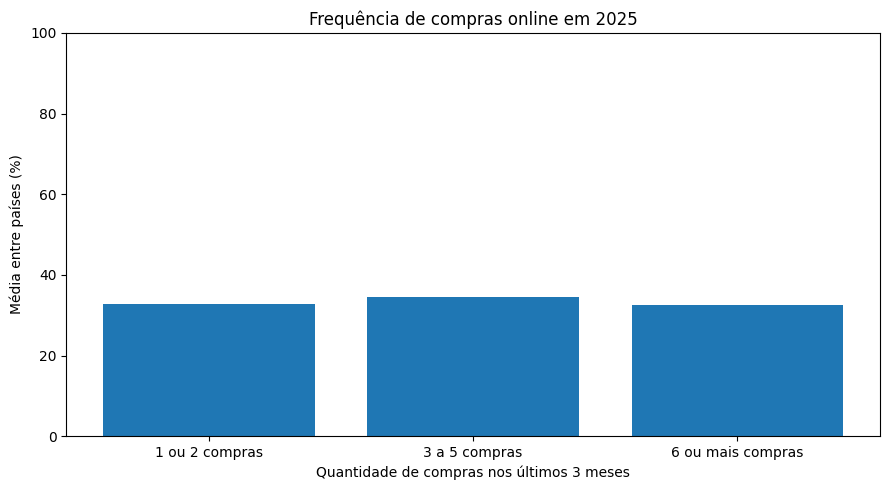

In [55]:
import matplotlib.pyplot as plt

media_frequencia = (
    df_frequencia.groupby('indic_is')['OBS_VALUE']
    .mean()
    .reindex(categorias_frequencia)
)

plt.figure(figsize=(9, 5))

plt.bar(
    ['1 ou 2 compras', '3 a 5 compras', '6 ou mais compras'],
    media_frequencia
)

plt.title('Frequência de compras online em 2025')
plt.xlabel('Quantidade de compras nos últimos 3 meses')
plt.ylabel('Média entre países (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 3. Preparação dos Dados (Data Preparation)

A etapa de preparação dos dados teve como objetivo organizar e tratar as informações disponibilizadas pelo Eurostat, garantindo condições adequadas para a realização das análises.

Inicialmente, o conjunto de dados apresentava 558.750 registros e 11 colunas. Foi realizada uma verificação de valores ausentes, identificando 27.912 registros sem informação na variável `OBS_VALUE`, responsável por armazenar os percentuais observados.

Esses registros foram removidos, resultando em uma base com 530.838 observações válidas. Também foi excluída a coluna `CONF_STATUS`, que não apresentava informações, e foram removidas as colunas técnicas `DATAFLOW`, `LAST UPDATE` e `freq`, por apresentarem valores constantes.

A verificação de duplicatas não identificou registros repetidos. A coluna `OBS_FLAG` foi mantida para preservar as informações relacionadas à qualidade das observações.

Em seguida, foram selecionados os indicadores, as unidades de medida e os grupos populacionais adequados aos objetivos do projeto. Para a análise da evolução temporal, utilizou-se o indicador referente à última compra online realizada nos três meses anteriores, considerando o percentual da população geral.

Foram identificadas 33 localidades com registros completos entre 2020 e 2025. Após a exclusão dos agregados regionais da União Europeia e da zona do euro, foi constituída uma base com 186 registros, correspondentes a 31 países acompanhados durante seis anos.

A base tratada completa foi preservada para permitir análises complementares por faixa etária e frequência de compras.

Esses procedimentos contribuíram para melhorar a consistência das comparações, reduzir problemas decorrentes de dados ausentes e preparar o conjunto de dados para as etapas seguintes da metodologia CRISP-DM.

## Etapa 4 — Modelagem (Modeling)

Nesta etapa, será aplicada uma regressão linear simples para investigar a tendência temporal da participação nas compras online entre 2020 e 2025.

O modelo utilizará o ano como variável independente e a média anual dos percentuais observados nos 31 países como variável dependente.

A escolha da regressão linear permite estimar a variação média anual e avaliar o grau de ajuste de uma tendência linear aos dados disponíveis.

Como a análise considera apenas seis observações anuais agregadas, os resultados serão interpretados de maneira exploratória, sem pretensão de realizar previsões precisas ou estabelecer relações de causa e efeito.

In [56]:
from sklearn.linear_model import LinearRegression

# Preparar os dados para a regressão
dados_modelo = (
    df_paises.groupby('TIME_PERIOD')['OBS_VALUE']
    .mean()
    .reset_index()
)

# Definir as variáveis
X = dados_modelo[['TIME_PERIOD']]
y = dados_modelo['OBS_VALUE']

# Criar e ajustar o modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Apresentar os resultados
print(
    'Variação estimada por ano:',
    round(modelo.coef_[0], 2),
    'pontos percentuais'
)

print(
    'R² do modelo:',
    round(modelo.score(X, y), 4)
)

Variação estimada por ano: 2.17 pontos percentuais
R² do modelo: 0.9251


### Resultados da regressão linear

Nesta etapa, utilizamos a biblioteca Scikit-learn para construir um modelo de regressão linear simples, considerando o período de 2020 a 2025.

A variável independente foi o ano, enquanto a variável dependente correspondeu à média anual dos percentuais de participação nas compras online entre os 31 países selecionados.

O modelo apresentou um coeficiente de regressão de aproximadamente 2,17 pontos percentuais por ano, indicando uma tendência linear positiva no período analisado.

O coeficiente de determinação (R²) foi de 0,9251, indicando que o modelo linear representa aproximadamente 92,51% da variação observada nas seis médias anuais.

Os resultados reforçam a tendência geral de crescimento identificada na análise exploratória.

Entretanto, o modelo apresenta limitações importantes. Foram utilizadas apenas seis observações anuais, calculadas a partir de médias simples entre países. Além disso, a regressão não considera diferenças demográficas, características específicas dos mercados ou fatores externos que possam influenciar o comportamento de compra.

Dessa forma, o modelo deve ser interpretado como uma representação estatística exploratória da tendência histórica, e não como uma ferramenta de previsão precisa ou de explicação causal.

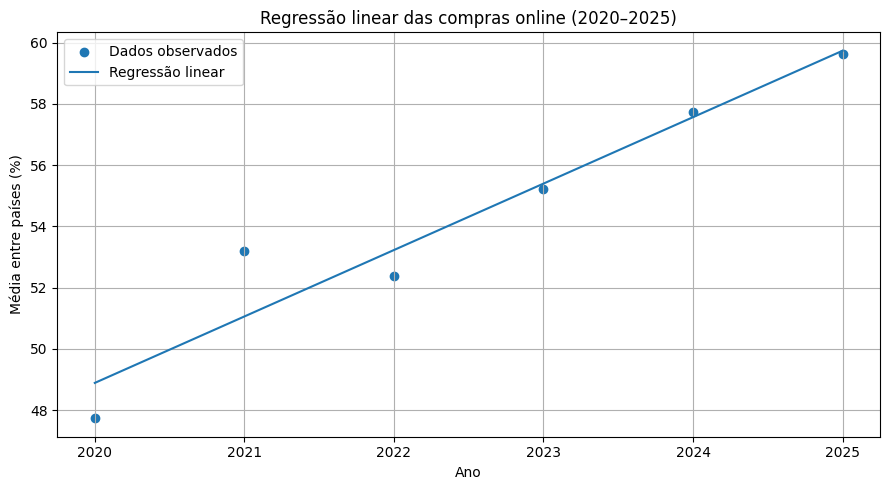

In [57]:
import matplotlib.pyplot as plt

# Calcular os valores estimados pelo modelo
dados_modelo['previsao'] = modelo.predict(X)

plt.figure(figsize=(9, 5))

plt.scatter(
    dados_modelo['TIME_PERIOD'],
    dados_modelo['OBS_VALUE'],
    label='Dados observados'
)

plt.plot(
    dados_modelo['TIME_PERIOD'],
    dados_modelo['previsao'],
    label='Regressão linear'
)

plt.title('Regressão linear das compras online (2020–2025)')
plt.xlabel('Ano')
plt.ylabel('Média entre países (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Visualização do modelo de regressão linear

Nesta etapa, utilizamos a biblioteca Matplotlib para representar graficamente os valores observados e os valores estimados pelo modelo de regressão linear.

O gráfico apresenta a evolução da média dos percentuais de compras online entre os 31 países analisados, no período de 2020 a 2025.

A linha de regressão apresenta uma tendência crescente, coerente com o coeficiente estimado de 2,17 pontos percentuais por ano.

Os pontos observados apresentam pequenas diferenças em relação à linha estimada, demonstrando que o crescimento não ocorreu de maneira perfeitamente linear.

O coeficiente de determinação de 0,9251 indica um ajuste elevado aos seis valores anuais utilizados. Entretanto, esse resultado não garante precisão para previsões futuras.

A visualização reforça a tendência histórica de crescimento das compras online, respeitando as limitações do modelo e dos dados agregados.

In [58]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    dados_modelo['OBS_VALUE'],
    dados_modelo['previsao']
)

print(
    'Erro absoluto médio (MAE):',
    round(mae, 2),
    'pontos percentuais'
)

Erro absoluto médio (MAE): 0.76 pontos percentuais


### Avaliação do modelo de regressão linear

Nesta etapa, avaliamos o ajuste do modelo de regressão linear utilizando o erro absoluto médio (MAE), calculado com a função `mean_absolute_error()` da biblioteca Scikit-learn.

O resultado obtido foi de 0,76 ponto percentual, indicando que a diferença absoluta média entre os valores observados e os estimados pelo modelo foi relativamente pequena.

Considerando também o coeficiente de determinação (R²) de 0,9251, verificamos que a regressão linear apresentou um bom ajuste à tendência histórica da média de participação nas compras online entre 2020 e 2025.

Entretanto, a avaliação foi realizada com as mesmas seis observações utilizadas no ajuste do modelo. Dessa forma, o MAE representa o erro de ajuste histórico, e não uma medida independente de desempenho preditivo.

Além disso, o modelo utiliza médias simples entre 31 países e não considera diferenças entre mercados, características demográficas ou fatores externos.

Concluímos que a regressão linear é adequada como ferramenta exploratória para representar a tendência observada no período analisado, mas seus resultados não devem ser utilizados isoladamente para realizar previsões futuras ou estabelecer relações de causa e efeito.

## Recomendações Estratégicas para o Marketing Digital

A análise dos dados do Eurostat, referentes ao período de 2020 a 2025, permitiu identificar tendências e diferenças no comportamento de compra online entre os 31 países selecionados.

Os resultados oferecem informações que podem contribuir para o planejamento de estratégias de Marketing Digital mais segmentadas e adequadas aos diferentes públicos.

### 1. Estratégias de segmentação geográfica

A média de participação nas compras online aumentou de 47,73% em 2020 para 59,62% em 2025, representando um crescimento de 11,89 pontos percentuais.

Entretanto, a evolução não ocorreu de maneira uniforme entre os países.

Chipre (+27,10 pontos percentuais), Grécia (+24,57) e Irlanda (+23,42) apresentaram alguns dos maiores crescimentos observados.

Esses resultados sugerem oportunidades para investigar mercados em expansão e desenvolver estratégias de comunicação adequadas às características de cada país.

Por outro lado, mercados com participação elevada e crescimento mais moderado podem demandar maior atenção ao relacionamento e à fidelização dos consumidores.

É importante destacar que a variação percentual, isoladamente, não permite determinar o potencial comercial de um mercado. Para decisões de investimento, seriam necessárias informações adicionais sobre concorrência, poder de compra e características dos consumidores.

### 2. Estratégias de segmentação demográfica

Em 2025, o grupo de 25 a 34 anos apresentou a maior média de participação nas compras online (75,87%), enquanto o grupo de 65 a 74 anos apresentou a menor (30,03%).

A diferença de 45,84 pontos percentuais indica que a participação no comércio eletrônico varia significativamente entre faixas etárias.

Para o Marketing Digital, esses resultados reforçam a importância de investigar as necessidades dos diferentes públicos, adaptando a linguagem, a apresentação das informações e a experiência de navegação.

Entretanto, os dados não permitem concluir quais fatores explicam essas diferenças. Portanto, recomendações específicas devem ser complementadas por pesquisas com consumidores.

### 3. Estratégias de relacionamento e fidelização

A análise da frequência de compras em 2025 apresentou médias relativamente próximas entre as três categorias investigadas:

- 1 ou 2 compras: 32,88%.
- 3 a 5 compras: 34,54%.
- 6 compras ou mais: 32,43%.

Esses resultados indicam diferentes intensidades de participação entre consumidores que compraram online nos últimos três meses.

Para as empresas, essa informação pode orientar a investigação de oportunidades de relacionamento, comunicação personalizada e fidelização.

Contudo, a base do Eurostat apresenta dados agregados e não permite identificar clientes individuais ou medir a eficácia de campanhas.

### Síntese das recomendações

Os resultados demonstram que o planejamento de Marketing Digital pode se beneficiar de uma abordagem orientada por dados, considerando diferenças geográficas, demográficas e comportamentais.

A principal recomendação é evitar estratégias generalizadas e utilizar os padrões identificados como ponto de partida para pesquisas mais específicas, testes de comunicação e decisões de negócio fundamentadas em evidências.

## Impacto Social e Inovação na Estratégia de Marketing Digital

### 1. Identificação da necessidade social

A transformação digital ampliou as possibilidades de acesso a produtos e serviços. Entretanto, a participação no comércio eletrônico não ocorre de maneira uniforme entre diferentes grupos da população.

Na análise dos dados do Eurostat referentes a 2025, observou-se que a média de participação nas compras online foi de **75,87% entre pessoas de 25 a 34 anos**, enquanto o grupo de **65 a 74 anos apresentou 30,03%**.

A diferença de **45,84 pontos percentuais**, calculada a partir das médias simples de 31 países, evidencia uma desigualdade de participação entre essas faixas etárias.

Esse resultado não comprova que a menor participação seja causada por dificuldades tecnológicas, problemas de acessibilidade ou falta de confiança. Entretanto, indica a importância de investigar possíveis barreiras na experiência de compra digital.

A necessidade social abordada neste projeto é, portanto, a promoção de uma comunicação digital mais clara, acessível e inclusiva.

### 2. Públicos afetados, benefícios e riscos

**Público 1 — Pessoas de 65 a 74 anos**

Esse grupo apresentou a menor participação média nas compras online entre as faixas etárias analisadas.

- **Benefício esperado:** maior facilidade para compreender informações sobre produtos, pagamentos, entregas e devoluções.
- **Risco:** campanhas baseadas apenas na idade podem reforçar estereótipos ou tratar os consumidores como incapazes.
- **Mitigação:** realizar pesquisas diretamente com os participantes e oferecer recursos de acessibilidade sem restringi-los a uma faixa etária.

**Público 2 — Pessoas de 25 a 34 anos**

Esse grupo apresentou a maior participação média nas compras online.

- **Benefício esperado:** acesso a informações mais claras e a processos de compra mais transparentes.
- **Risco:** a personalização excessiva pode gerar comunicação invasiva ou utilização inadequada de dados pessoais.
- **Mitigação:** adotar práticas de privacidade, transparência e coleta mínima de informações, respeitando a legislação aplicável.

A proposta também poderá beneficiar consumidores de outras idades que enfrentem dificuldades na utilização de plataformas digitais.

### 3. Evidências utilizadas

**Fonte:** Eurostat — conjunto de dados `isoc_ec_ib20`.

**Período:** 2025.

**População analisada:** indivíduos distribuídos em seis faixas etárias, de 16 a 74 anos, nos 31 países selecionados.

**Indicador:** percentual de indivíduos cuja última compra online ocorreu nos três meses anteriores.

**Resultados observados:**

- Pessoas de 25 a 34 anos: 75,87%.
- Pessoas de 65 a 74 anos: 30,03%.
- Diferença entre os grupos: 45,84 pontos percentuais.

Os resultados são médias simples entre países e não representam percentuais ponderados pela população europeia.

Além disso, os dados não permitem identificar individualmente as dificuldades enfrentadas pelos consumidores nem determinar as causas das diferenças observadas.

Assim, a investigação de possíveis barreiras de acessibilidade constitui uma hipótese para uma intervenção futura.

### 4. Proposta de inovação social

**Nome da proposta: Comunicação Digital Acessível para Compras Online**

Propõe-se desenvolver uma iniciativa de melhoria da comunicação em plataformas de comércio eletrônico, com foco na clareza das informações e na facilidade de utilização dos canais digitais.

**Ações previstas:**

1. Revisar descrições de produtos utilizando linguagem clara e objetiva.
2. Criar orientações passo a passo para o processo de compra.
3. Destacar informações sobre pagamentos, entrega, trocas e devoluções.
4. Melhorar a legibilidade dos textos e a organização visual das páginas.
5. Disponibilizar canais acessíveis para esclarecimento de dúvidas.
6. Realizar testes de compreensão e navegação com consumidores de diferentes faixas etárias.

**Público prioritário:** consumidores de 65 a 74 anos, sem excluir outros grupos.

**Canais:** site de comércio eletrônico, páginas de produtos, e-mail e conteúdos informativos em redes sociais.

**Recursos necessários:** equipe de Marketing, profissionais de experiência do usuário, ferramentas de pesquisa e participantes voluntários para testes.

**Objetivo de negócio:** melhorar a experiência de compra e reduzir dificuldades que possam prejudicar a conclusão de compras.

**Benefício social esperado:** facilitar a compreensão das informações e ampliar a acessibilidade da experiência de compra digital.

**Riscos e mitigação:** evitar estereótipos etários, garantir participação voluntária nos testes e proteger os dados pessoais coletados.

A iniciativa é uma proposta de inovação social e **não foi implementada durante este projeto**.

### 5. Indicadores para avaliar o impacto

Para verificar os resultados da proposta, foram definidos quatro indicadores de acompanhamento.

| Indicador | Como medir | Quando medir |
|---|---|---|
| Percentual de conteúdos revisados | Número de conteúdos que atendem à lista de verificação de acessibilidade dividido pelo total de conteúdos avaliados, multiplicado por 100 | Antes e depois da revisão |
| Taxa de compreensão das informações | Percentual de participantes que respondem corretamente a perguntas sobre pagamento, entrega e devolução | Nos testes da versão original e da versão revisada |
| Taxa de conclusão de compra simulada | Percentual de participantes que conseguem concluir uma compra simulada sem ajuda | Nos testes da versão original e da versão

## Considerações Finais

Este projeto teve como objetivo analisar a evolução das compras online em países europeus entre 2020 e 2025, investigando diferenças geográficas e demográficas no comportamento dos consumidores e identificando oportunidades para estratégias de Marketing Digital mais eficazes e inclusivas.

A investigação foi desenvolvida com dados públicos do Eurostat, utilizando a metodologia CRISP-DM e técnicas de preparação de dados, análise exploratória, estatística descritiva, visualização e regressão linear simples.

### Principais resultados

A análise temporal identificou uma tendência geral de crescimento da participação nas compras online. A média entre os 31 países selecionados passou de **47,73% em 2020 para 59,62% em 2025**, representando um aumento de **11,89 pontos percentuais**.

Entretanto, a comparação geográfica demonstrou que essa evolução não ocorreu de maneira uniforme. Chipre (+27,10 pontos percentuais), Grécia (+24,57) e Irlanda (+23,42) apresentaram alguns dos maiores crescimentos, enquanto a Alemanha registrou uma redução de 4,62 pontos percentuais no período.

Na análise demográfica de 2025, observou-se que o grupo de **25 a 34 anos apresentou a maior média de participação nas compras online (75,87%)**, enquanto o grupo de **65 a 74 anos apresentou a menor (30,03%)**. A diferença de 45,84 pontos percentuais evidencia a importância de considerar as características dos diferentes públicos nas estratégias digitais.

A investigação da frequência de compras também revelou uma distribuição relativamente equilibrada entre os consumidores que realizaram compras online nos últimos três meses: 32,88% realizaram uma ou duas compras, 34,54% realizaram de três a cinco compras e 32,43% realizaram seis compras ou mais.

### Resultados da modelagem

Na etapa de modelagem, foi aplicada uma regressão linear simples para representar a tendência temporal da média de participação nas compras online.

O modelo apresentou uma variação estimada de **2,17 pontos percentuais por ano**, um coeficiente de determinação (**R²**) de **0,9251** e um erro absoluto médio (**MAE**) de **0,76 ponto percentual**.

Esses resultados indicam que a regressão apresentou bom ajuste aos dados históricos utilizados.

Entretanto, o modelo foi desenvolvido com apenas seis observações anuais e avaliado sobre os mesmos dados utilizados em seu ajuste. Portanto, os resultados não comprovam capacidade de previsão futura nem permitem estabelecer relações de causa e efeito.

### Contribuições para o Marketing Digital

Os resultados reforçam a importância de utilizar dados para compreender diferenças entre mercados e perfis de consumidores.

A análise geográfica pode contribuir para a identificação de mercados que merecem investigação mais aprofundada, enquanto as diferenças demográficas destacam a relevância de adaptar a comunicação e a experiência digital às necessidades dos públicos.

A análise da frequência de compras também oferece informações que podem orientar pesquisas sobre relacionamento e fidelização de consumidores.

Contudo, as decisões empresariais devem considerar informações complementares, como características dos mercados, concorrência, preferências dos consumidores e resultados de campanhas específicas.

### Impacto social e inovação

Além das oportunidades de negócio, o projeto identificou diferenças relevantes na participação nas compras online entre faixas etárias.

A menor participação média observada entre pessoas de 65 a 74 anos motivou a elaboração de uma proposta de **Comunicação Digital Acessível para Compras Online**.

A iniciativa prevê melhorias na clareza das informações, na organização dos conteúdos e na facilidade de navegação, acompanhadas por testes de compreensão e realização de tarefas.

A proposta busca conciliar um objetivo empresarial — melhorar a experiência de compra — com um benefício social esperado: tornar a comunicação digital mais acessível a diferentes consumidores.

Entretanto, os dados analisados não demonstram quais fatores causam as diferenças entre faixas etárias, e a intervenção proposta ainda não foi implementada.

Assim, seus possíveis benefícios deverão ser avaliados futuramente por meio de indicadores, medições iniciais e comparações posteriores.

### Limitações do estudo

Entre as principais limitações, destacam-se:

- Utilização de dados estatísticos agregados, sem informações individuais sobre consumidores.
- Cálculo de médias simples entre países, sem ponderação pelo tamanho das populações.
- Restrição da análise temporal a 31 países com dados completos entre 2020 e 2025.
- Impossibilidade de identificar diretamente as causas das diferenças observadas.
- Utilização de apenas seis observações anuais na regressão linear.
- Ausência de validação preditiva independente.
- Ausência de testes práticos da proposta de inovação social.

### Conclusão

Conclui-se que o uso de técnicas de Ciência de Dados permitiu identificar tendências e diferenças relevantes no comportamento de compra online em países europeus.

A aplicação da metodologia CRISP-DM contribuiu para organizar o processo de investigação, desde a definição do problema até a interpretação dos resultados e a elaboração de recomendações.

O projeto demonstra que a análise de dados pode apoiar decisões de Marketing Digital, oferecendo informações para compreender mercados, investigar segmentos de consumidores e orientar estratégias de comunicação.

Ao mesmo tempo, evidencia a importância de considerar a dimensão social dessas decisões, buscando soluções que conciliem objetivos de negócio com uma experiência digital mais acessível e inclusiva.

Dessa forma, o trabalho alcança seu objetivo exploratório e apresenta possibilidades de aprofundamento por meio de novas pesquisas, testes com consumidores e avaliação de iniciativas de Marketing Digital.